# Cross-matching literature transients

Each section crossmatches one target list against the catalog (5"), then plots the matches.

In [28]:
import os
import sys
from glob import glob

import h5py
import numpy as np
import pandas as pd
import astropy.units as u
import matplotlib.pyplot as plt
from astropy.table import Table, meta as table_meta, serialize
from astropy.coordinates import SkyCoord

sys.path.append('/Users/adamboesky/Research/long_transients')
sys.path.append('/n/home04/aboesky/berger/long_transients')

from Extracting.utils import get_data_path
from Source_Analysis.Sources import Source, Sources, MANDATORY_SOURCE_COLUMNS
from Source_Analysis.local_store import LocalStore

## Setup

In [29]:
CAT_DIR = f'{get_data_path()}/filter_results_9_21_2026_full_catalog_fixed_pm/combined'
FILTERING_DIR = CAT_DIR if glob(f'{CAT_DIR}/*_filtered_out.ecsv') else os.path.dirname(CAT_DIR)
ZTF_DATA_DIR = os.path.join(get_data_path(), 'ztf_data')
MATCH_ARCSEC = 5.0

# Light curves + catalog rows from Data/db (built from CAT_DIR); cutouts/spectra stay live.
STORE = LocalStore()

cats = {}
for f in ['0.hdf5', '1.hdf5']:
    with h5py.File(f'{CAT_DIR}/{f}', 'r') as h:
        radec = h['data'].fields(['ra', 'dec'])[:]
    cats[f] = SkyCoord(radec['ra'] * u.deg, radec['dec'] * u.deg)
    print(f'{f}: {len(cats[f])} sources, dec {cats[f].dec.deg.min():.2f} to {cats[f].dec.deg.max():.2f}')

0.hdf5: 186970 sources, dec -27.93 to 87.46
1.hdf5: 10935 sources, dec -27.89 to 87.46


In [30]:
def load_ecsv_rows(fpath: str, rows, path: str = 'data') -> Table:
    """load_ecsv(fpath)[rows], reading only those rows off disk (str columns stay bytes)."""
    rows = np.atleast_1d(np.asarray(rows, dtype=int))
    with h5py.File(fpath, 'r') as f:
        dset = f[path]
        uniq, inverse = np.unique(rows, return_inverse=True)  # h5py needs sorted, unique indices
        table = Table(dset[uniq.tolist()][inverse], copy=False)

        meta_name = f'{path}.__table_column_meta__'
        if meta_name in f:
            header = table_meta.get_header_from_yaml(h.decode('utf-8') for h in f[meta_name])
            if 'meta' in header:
                table.meta = header['meta']
            header_cols = {x['name']: x for x in header['datatype']}
            for col in table.columns.values():
                for attr in ('description', 'format', 'unit', 'meta'):
                    if attr in header_cols[col.name]:
                        setattr(col, attr, header_cols[col.name][attr])
            table = serialize._construct_mixins_from_columns(table)
        else:
            table.meta.update(dset.attrs)
    return table


def crossmatch(targets):
    """Print nearest-catalog separations for [(name, ra, dec)].

    Returns (hits, misses): hits = [(name, file, row)], misses = [(name, ra, dec)].
    """
    hits, misses = [], []
    for name, ra, dec in targets:
        c = SkyCoord(ra * u.deg, dec * u.deg)
        parts, best = [], np.inf
        for f, cat in cats.items():
            sep = c.separation(cat).arcsec
            i = int(sep.argmin())
            best = min(best, sep[i])
            parts.append(f'{f}: {sep[i]:.2f}" (idx {i})')
            if sep[i] < MATCH_ARCSEC:
                hits.append((name, f, i))
        if best >= MATCH_ARCSEC:
            misses.append((name, ra, dec))
        print(f'  {"*** MATCH " if best < MATCH_ARCSEC else "  no match"} {name:26s} {" | ".join(parts)}')
    return hits, misses


def load_hits(hits) -> dict:
    """{name: Source} for crossmatch hits."""
    srcs = {}
    for f in sorted({f for _, f, _ in hits}):
        names, rows = zip(*[(n, i) for n, ff, i in hits if ff == f])
        loaded = Sources.from_table(load_ecsv_rows(f'{CAT_DIR}/{f}', rows), store=STORE,
                                    ztf_data_dir=ZTF_DATA_DIR, filtering_dirpath=FILTERING_DIR)
        for name, src in zip(names, loaded):
            srcs[name] = src
            d = src.data
            print(f'{name:26s} [{f}] ra={src.ra:.6f} dec={src.dec:.6f}  '
                  f'ZTF g/r/i = {d["ZTF_gPSFMag"][0]:.2f}/{d["ZTF_rPSFMag"][0]:.2f}/{d["ZTF_iPSFMag"][0]:.2f}  '
                  f'PS1 g/r/i = {d["PSTARR_gPSFMag"][0]:.2f}/{d["PSTARR_rPSFMag"][0]:.2f}/{d["PSTARR_iPSFMag"][0]:.2f}')
    return srcs


def uncatalogued_source(ra: float, dec: float) -> Source:
    """Source for a position not in the catalog, with a blank (all-NaN) catalog row.

    The row stops Source.data falling back to per-field catalogs we don't have locally.
    ZTF image metadata is resolved by coordinate first, since with a row present it is
    read off the row instead.
    """
    src = Source(ra, dec, store=STORE, ztf_data_dir=ZTF_DATA_DIR)
    meta = src.image_metadata
    row = Table({c: [np.nan] for c in MANDATORY_SOURCE_COLUMNS})
    row['ra'], row['dec'] = [ra], [dec]
    for k in ('fieldid', 'ccdid', 'qid'):
        row[k] = [meta[k]]
    src.data = row
    return src

## Masterson+24 / Nair+26 (WISE-selected TDEs)

In [31]:
m24 = [("WTP14abnpgk / AT2022mim",251.477888,-23.451942),("WTP14acnjbu",264.328943,19.292112),
("WTP14adbjsh",342.953459,-20.608018),("WTP14adbwvs",198.748944,51.272774),("WTP14adeqka",297.353597,63.509271),
("WTP15abymdq",57.219702,-55.426525),("WTP15acbgpn",166.258054,59.684626),("WTP15acbuuv",154.672586,-13.001884),
("WTP16aaqrcr",280.829573,-62.112048),("WTP16aatsnw",254.844458,20.8298),("WTP17aaldjb",197.064964,4.485906),
("WTP17aalzpx",50.856858,-2.046782),("WTP17aamoxe",317.242691,-56.475355),("WTP17aamzew",146.2357,31.097848),
("WTP17aanbso",180.909755,58.986509),("WTP18aajkmk",40.099143,-2.728314),("WTP18aamced / AT2018dyk",233.283417,44.535533),
("WTP18aampwj / AT2018gn",26.676815,32.508168)]
n26 = [("WTP14actvjz",56.086780,-49.8646),("WTP14adauec",145.1229851,37.135161),("WTP15abwlqq",307.784893,-50.6332941),
("WTP15abzxqe",228.4378545,-86.740893473),("WTP16aapkfo",48.966392,-0.9921),("WTP17aaiyxe",229.341644,46.9701932),
("WTP17aakzqt",45.697713,-65.742939),("WTP17aanbho / AT2017fot",346.6021038,-7.272606812),
("WTP18aamykg",53.707291,25.033717),("WTP19aajfdd",60.46709897,-24.4161968)]

In [32]:
wise_hits = []
for label, targets in [('Masterson+24 (ad18bb)', m24), ('Nair+26 (ae83a1)', n26)]:
    print(f'=== {label} ===')
    wise_hits += crossmatch(targets)[0]

print()
wise_srcs = load_hits(wise_hits)

=== Masterson+24 (ad18bb) ===
    no match WTP14abnpgk / AT2022mim    0.hdf5: 62523.27" (idx 85213) | 1.hdf5: 67049.72" (idx 3657)
  *** MATCH  WTP14acnjbu                0.hdf5: 1.00" (idx 25012) | 1.hdf5: 6971.40" (idx 818)
    no match WTP14adbjsh                0.hdf5: 27.88" (idx 3066) | 1.hdf5: 842.01" (idx 61)
    no match WTP14adbwvs                0.hdf5: 3552.29" (idx 186879) | 1.hdf5: 12485.28" (idx 3692)
    no match WTP14adeqka                0.hdf5: 487.06" (idx 133400) | 1.hdf5: 8430.97" (idx 7610)
    no match WTP15abymdq                0.hdf5: 124889.47" (idx 119578) | 1.hdf5: 125372.29" (idx 4554)
    no match WTP15acbgpn                0.hdf5: 615.13" (idx 2698) | 1.hdf5: 2344.18" (idx 40)
    no match WTP15acbuuv                0.hdf5: 461.63" (idx 140205) | 1.hdf5: 1487.19" (idx 7799)
    no match WTP16aaqrcr                0.hdf5: 158089.93" (idx 100200) | 1.hdf5: 164491.87" (idx 10695)
    no match WTP16aatsnw                0.hdf5: 6219.48" (idx 118265) | 1.hdf5

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000587+AND+ccdid=12+AND+qid=4

Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000587_zg_c12_q4_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000587_zi_c12_q4_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000587_zr_c12_q4_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Source at (264.32922585988285, 19.292035322147974) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

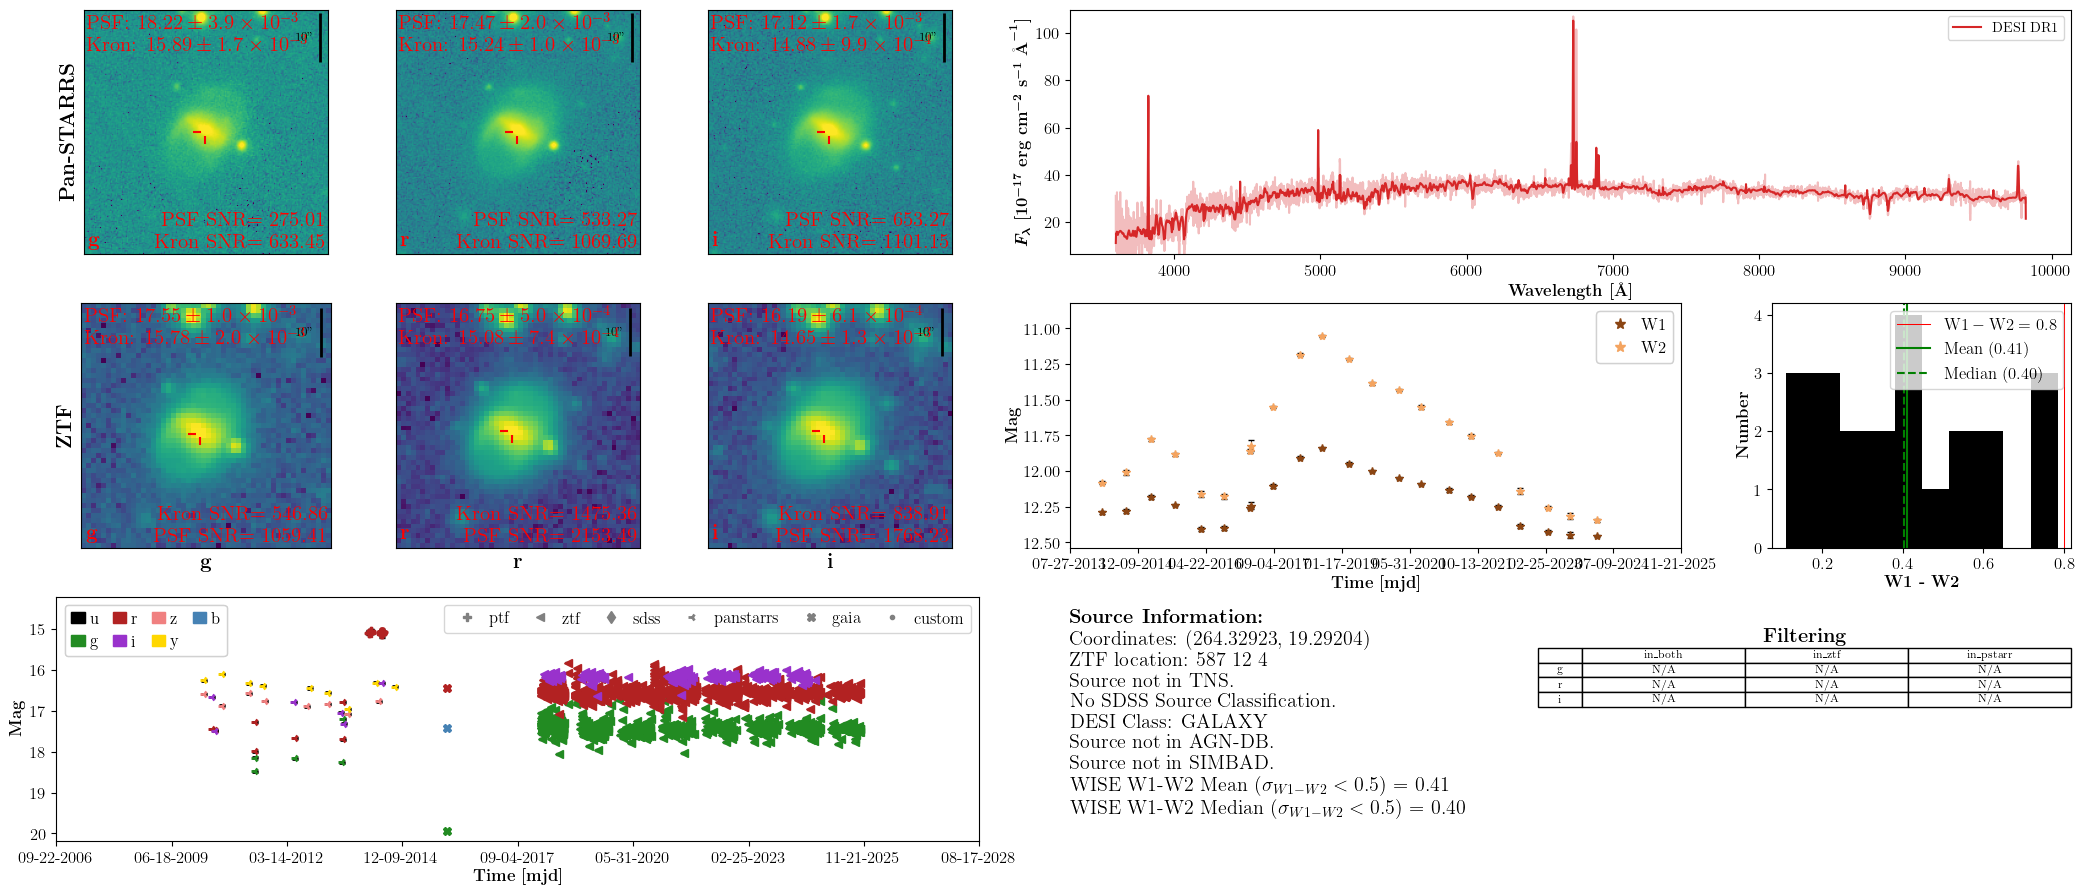

In [33]:
wise_srcs['WTP14acnjbu'].plot_everything()

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000651+AND+ccdid=05+AND+qid=2



python(62212) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpjldzl83p/ztf_000651_zi_c05_q2_refimg.fits


python(62216) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmpo80s2lus/ztf_000651_zg_c05_q2_refimg.fits


...

Image downloaded and saved at /var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/tmppqkgjcqw/ztf_000651_zr_c05_q2_refimg.fits
Querying ztf catalog for light curve...Querying wise catalog for light curve...

Querying neowise catalog for light curve...
Querying ptf catalog for light curve...
Querying sdss catalog for light curve...
Querying panstarrs catalog for light curve...
Querying gaia catalog for light curve...
Querying custom catalog for light curve...


/Users/adamboesky/Research/long_transients/Source_Analysis/Light_Curve.py:609: RuntimeWarning: Mean of empty slice
  mean_val = np.nanmean(col_data)
/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1256: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  kwargs.setdefault(key, value)


Source at (26.6767938707824, 32.50807136126751) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (26.6767938707824, 32.50807136126751) has no spectrum in DESI DR1.


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1391: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  }
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

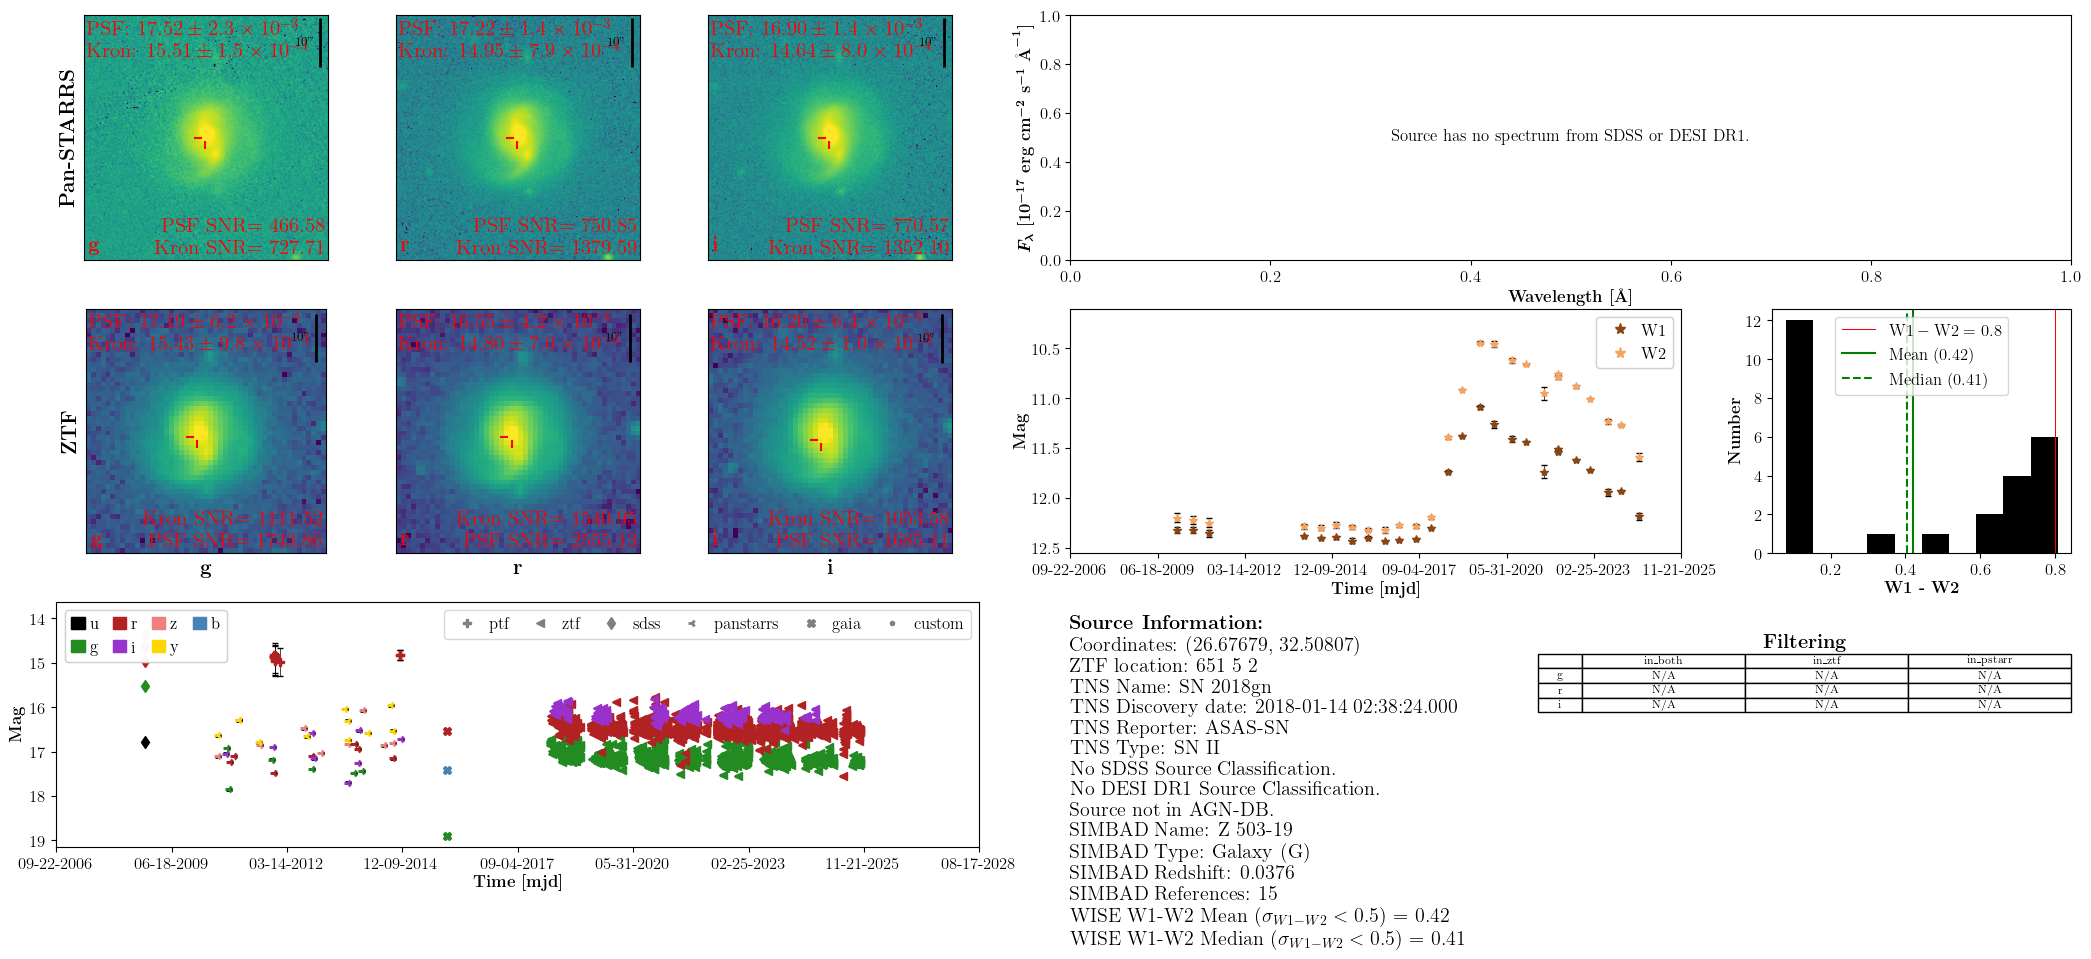

In [17]:
wise_srcs['WTP18aampwj / AT2018gn'].plot_everything()

## ANTs (ANTs-Nest)

Only `ant_properties.csv` has coordinates (13 ANTs). AT2019fdr and AT2020adpi are plotted in the JWST section.

In [34]:
ants = pd.read_csv('/Users/adamboesky/Research/long_transients/ANTs-Nest/ant_properties.csv').dropna(subset=['RA', 'Dec'])
ant_targets = [(a['ZTF ID'] if a['IAU name'] == '-' else a['IAU name'], a['RA'], a['Dec']) for _, a in ants.iterrows()]

ant_hits, _ = crossmatch(ant_targets)
print()
ant_srcs = load_hits(ant_hits)

    no match AT2021lwx                  0.hdf5: 3250.91" (idx 13465) | 1.hdf5: 14780.82" (idx 350)
    no match ZTF19aamrjar               0.hdf5: 11874.03" (idx 25203) | 1.hdf5: 19581.81" (idx 843)
    no match AT2020afep                 0.hdf5: 783.15" (idx 150125) | 1.hdf5: 5574.57" (idx 3750)
  *** MATCH  AT2019kn                   0.hdf5: 0.08" (idx 33568) | 1.hdf5: 3831.73" (idx 968)
  *** MATCH  AT2021yzu                  0.hdf5: 0.18" (idx 85732) | 1.hdf5: 5845.87" (idx 3688)
    no match AT2019brs                  0.hdf5: 460.68" (idx 29141) | 1.hdf5: 4077.80" (idx 8727)
    no match AT2020oio                  0.hdf5: 4785.73" (idx 155966) | 1.hdf5: 11595.17" (idx 8900)
    no match AT2022fpx                  0.hdf5: 642.32" (idx 115973) | 1.hdf5: 2598.07" (idx 4453)
    no match AT2018lcp                  0.hdf5: 471.39" (idx 131360) | 1.hdf5: 3464.87" (idx 7579)
    no match AT2022zg                   0.hdf5: 979.06" (idx 178185) | 1.hdf5: 5136.13" (idx 10600)
  *** MATCH  A

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000451+AND+ccdid=14+AND+qid=3

Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000451_zr_c14_q3_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000451_zg_c14_q3_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000451_zi_c14_q3_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Source at (33.790940498330116, 7.164519126081355) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

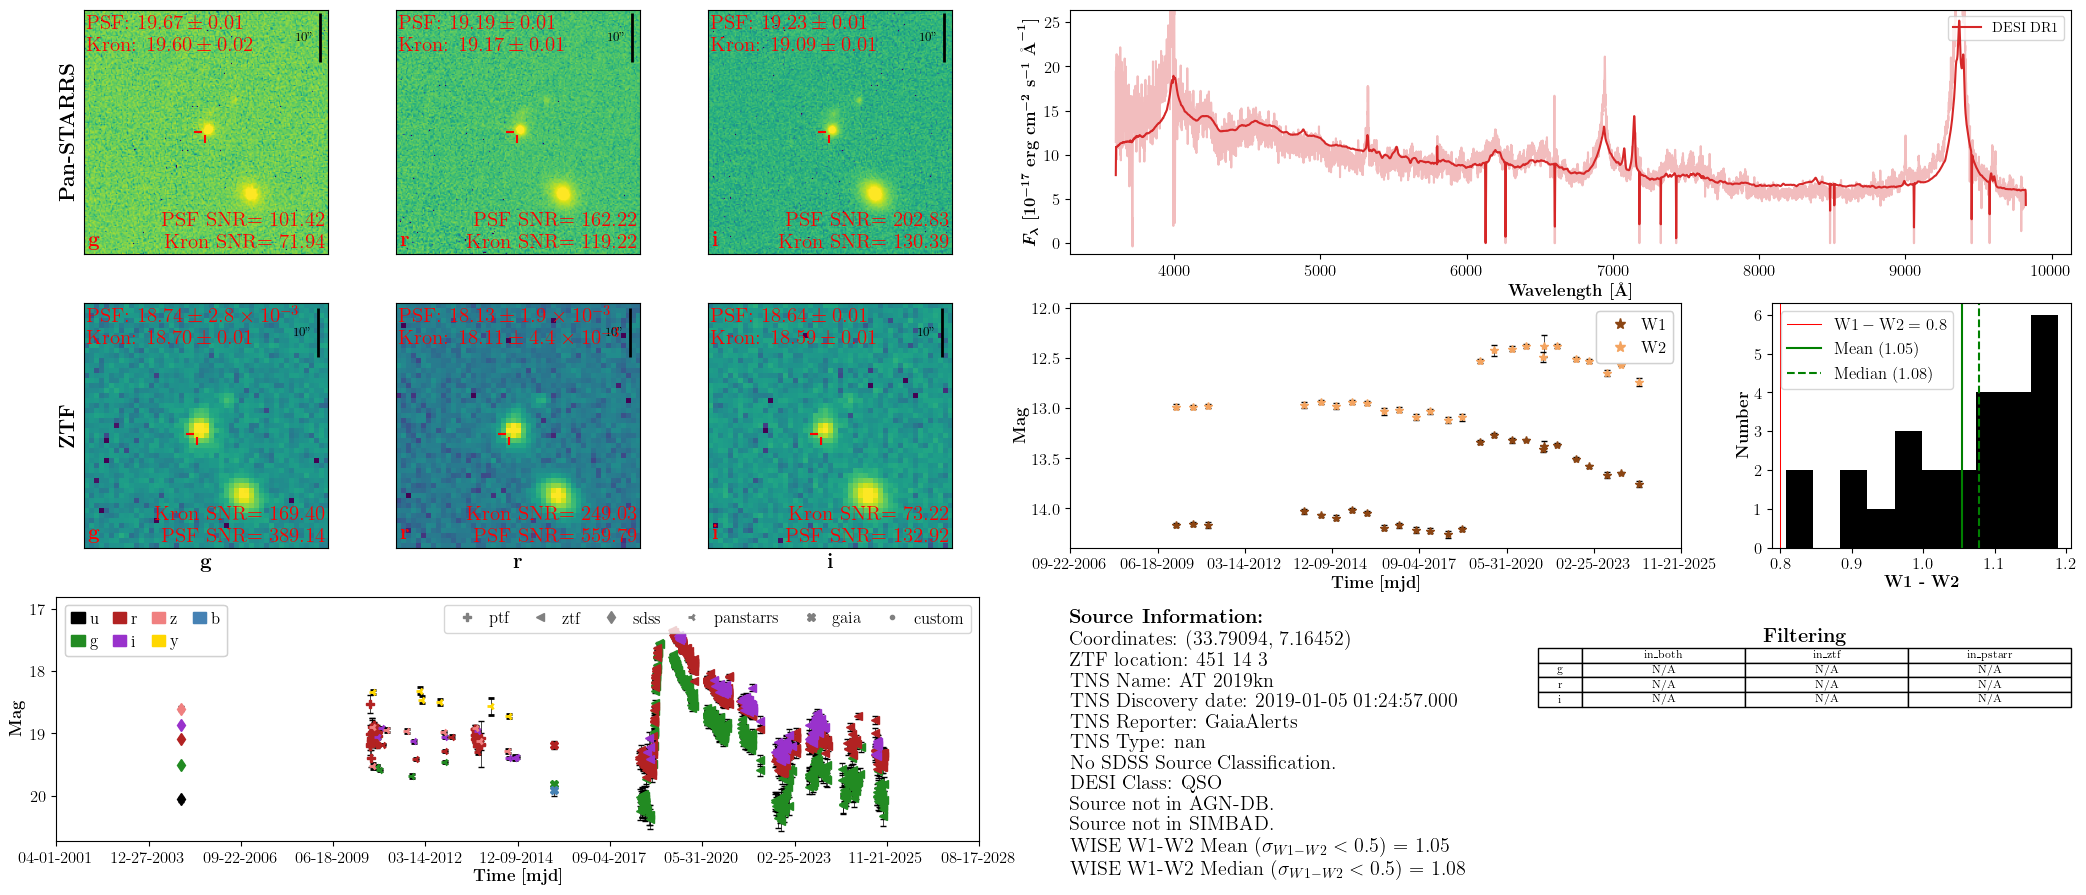

In [35]:
ant_srcs['AT2019kn'].plot_everything()

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000390+AND+ccdid=06+AND+qid=1
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000390_zg_c06_q1_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000390_zi_c06_q1_refimg.fits
Image downloaded and saved at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000390_zr_c06_q1_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Source at (324.33308629049225, -10.753330121944161) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (324.33308629049225, -10.753330121944161) has no spectrum in DESI DR1.


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

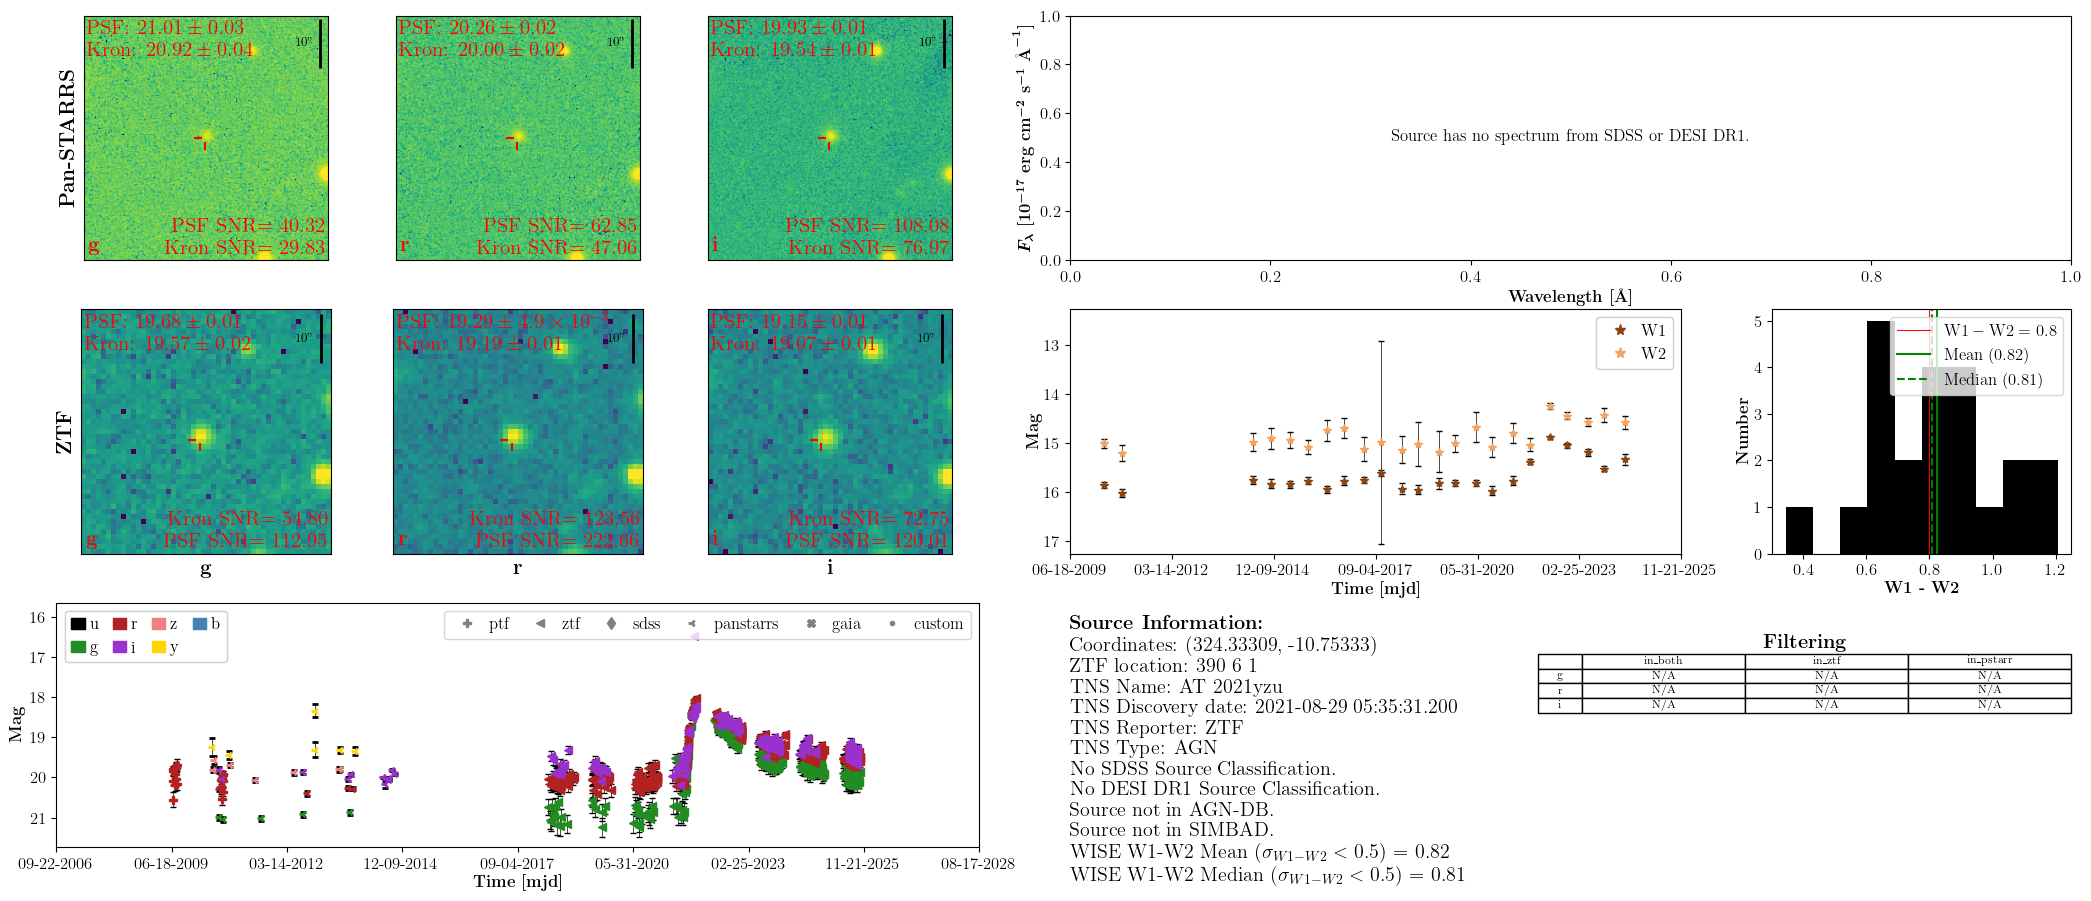

In [36]:
ant_srcs['AT2021yzu'].plot_everything()

## JWST proposal

Each plot is also saved to `~/Desktop/{name}.pdf`.

In [37]:
jwst = [("SN 2016ezh", 29.5197461458, -0.872704525881),
        ("AT 2017fro", 259.982708, 41.680411),
        ("AT 2017gge", 245.145848471, 24.1240483896),
        ("AT 2019avd", 125.9031975, 4.3840166),
        ("SN 2019fdr", 257.278578935, 26.8556946632),
        ("AT 2020adpi", 349.724042, -10.58495),
        ("TDE 2022fpx", 232.765417, 53.40535)]

jwst_hits, jwst_misses = crossmatch(jwst)
print()
jwst_srcs = load_hits(jwst_hits)


def plot_and_save(srcs: dict, name: str):
    """plot_everything for srcs[name], saved to ~/Desktop/{name}.pdf."""
    srcs[name].plot_everything()
    plt.savefig(os.path.expanduser(f'~/Desktop/{name}.pdf'), bbox_inches='tight')

  *** MATCH  SN 2016ezh                 0.hdf5: 0.24" (idx 97389) | 1.hdf5: 3651.33" (idx 3851)
    no match AT 2017fro                 0.hdf5: 401.73" (idx 95215) | 1.hdf5: 9444.46" (idx 3829)
    no match AT 2017gge                 0.hdf5: 1062.35" (idx 19123) | 1.hdf5: 4281.74" (idx 3811)
  *** MATCH  AT 2019avd                 0.hdf5: 0.08" (idx 58222) | 1.hdf5: 401.88" (idx 2172)
  *** MATCH  SN 2019fdr                 0.hdf5: 0.10" (idx 118490) | 1.hdf5: 9034.62" (idx 4533)
  *** MATCH  AT 2020adpi                0.hdf5: 0.09" (idx 34635) | 1.hdf5: 2767.39" (idx 997)
    no match TDE 2022fpx                0.hdf5: 642.32" (idx 115973) | 1.hdf5: 2598.05" (idx 4453)

SN 2016ezh                 [0.hdf5] ra=29.519777 dec=-0.872763  ZTF g/r/i = 17.91/17.37/nan  PS1 g/r/i = 19.11/18.79/nan
AT 2019avd                 [0.hdf5] ra=125.903214 dec=4.384002  ZTF g/r/i = 17.26/16.66/16.17  PS1 g/r/i = 17.92/17.04/16.90
SN 2019fdr                 [0.hdf5] ra=257.278547 dec=26.855689  ZTF g/r/i


Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000400+AND+ccdid=11+AND+qid=1

Checking if image already downloaded and valid: ztf_000400_zr_c11_q1_refimg.fits
Checking if image already downloaded and valid: ztf_000400_zg_c11_q1_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000400_zr_c11_q1_refimg.fitsImage is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000400_zg_c11_q1_refimg.fits

Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Getting source spectrum from SDSS (spec-1075-52933-0140.fits)...
Getting source spectrum from DESI DR1 (SPARCL)...


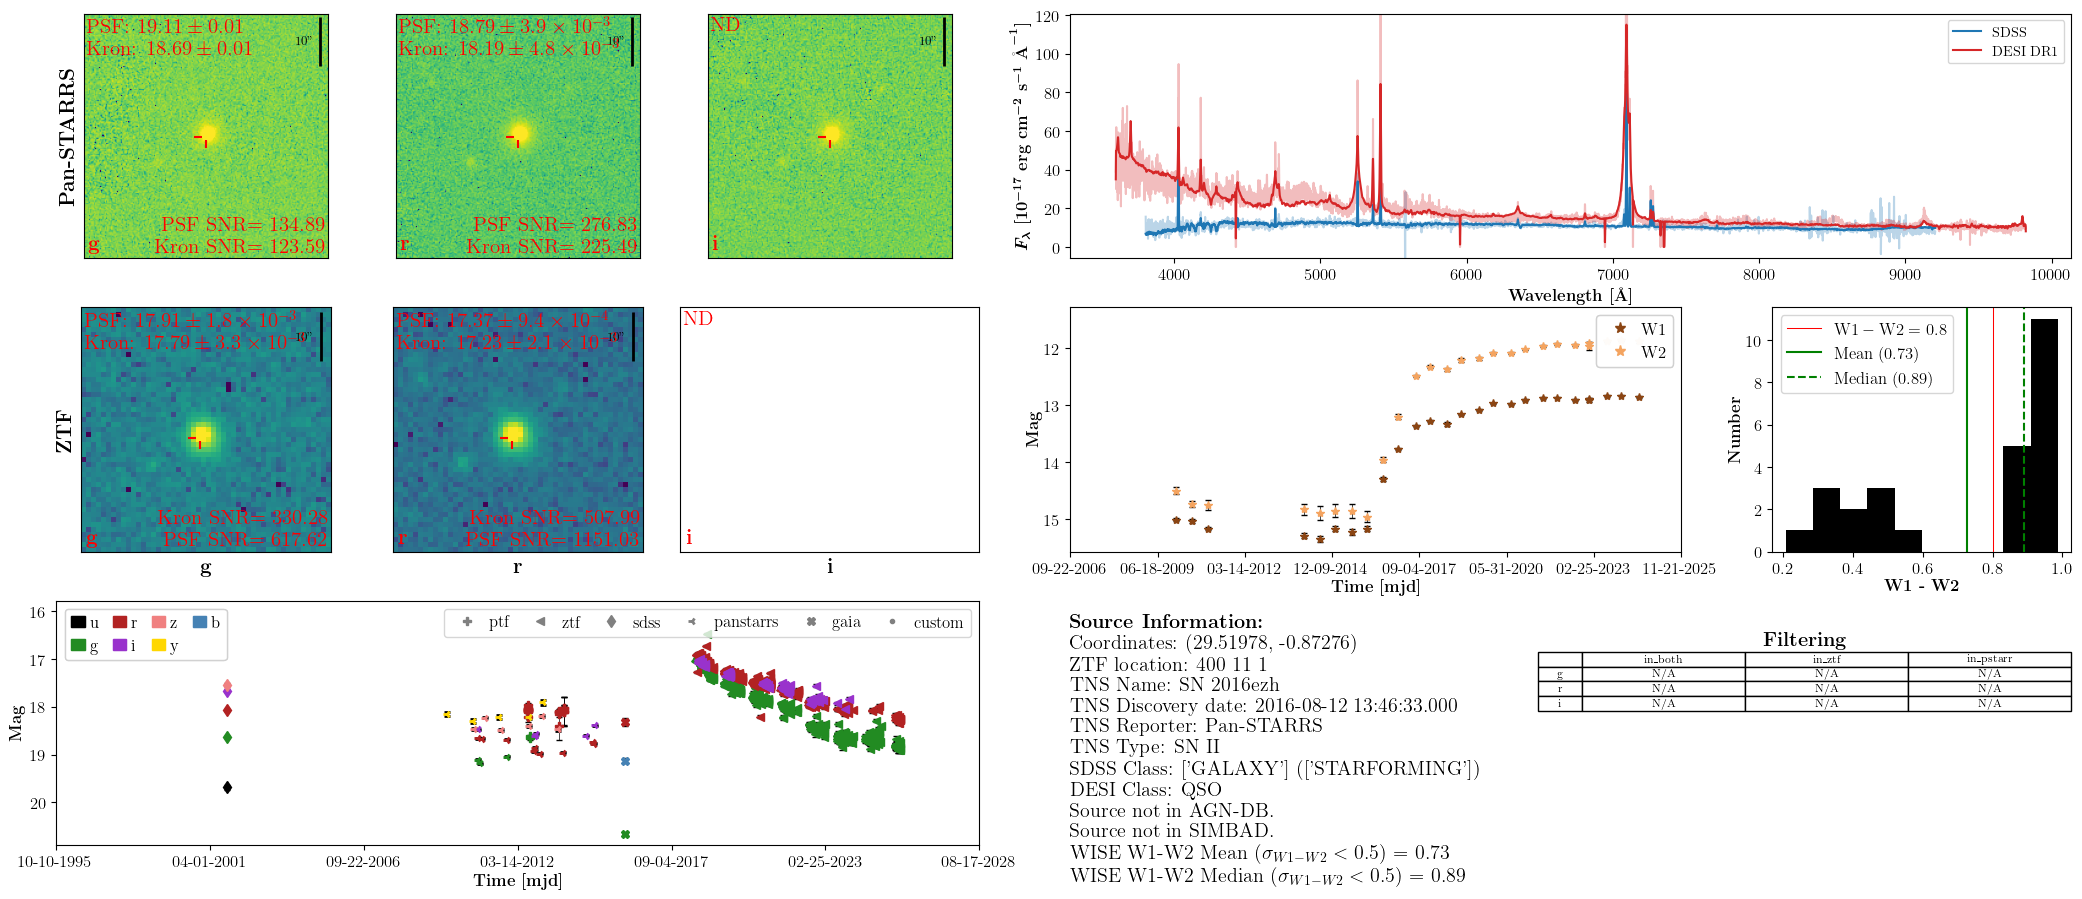

In [38]:
plot_and_save(jwst_srcs, 'SN 2016ezh')

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000464+AND+ccdid=05+AND+qid=2

Checking if image already downloaded and valid: ztf_000464_zg_c05_q2_refimg.fits
Checking if image already downloaded and valid: ztf_000464_zr_c05_q2_refimg.fits
Checking if image already downloaded and valid: ztf_000464_zi_c05_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000464_zr_c05_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000464_zg_c05_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000464_zi_c05_q2_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Source at (125.90321389348786, 4.384001556794008) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...


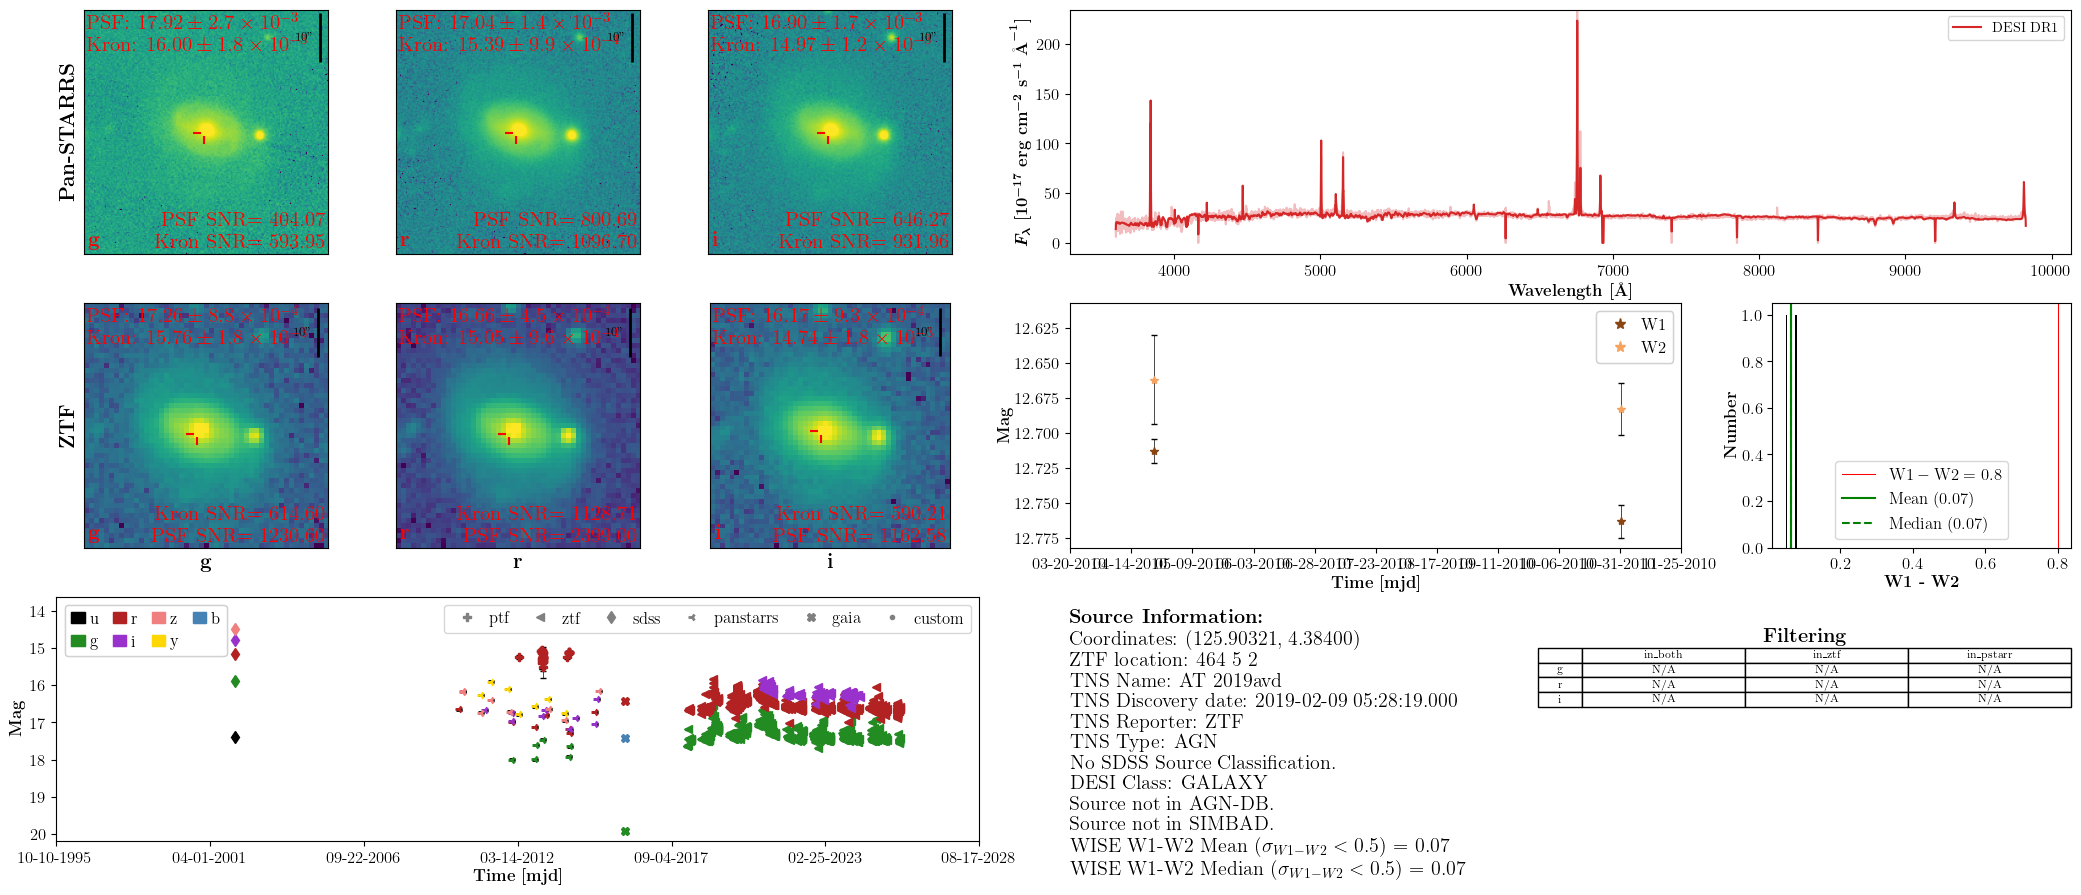

In [39]:
plot_and_save(jwst_srcs, 'AT 2019avd')

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000634+AND+ccdid=10+AND+qid=4

Checking if image already downloaded and valid: ztf_000634_zg_c10_q4_refimg.fits
Checking if image already downloaded and valid: ztf_000634_zi_c10_q4_refimg.fits
Checking if image already downloaded and valid: ztf_000634_zr_c10_q4_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000634_zg_c10_q4_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000634_zi_c10_q4_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000634_zr_c10_q4_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Source at (257.27854733996173, 26.85568896307101) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (257.27854733996173, 26.85568896307101) has no spectrum in DESI DR1.


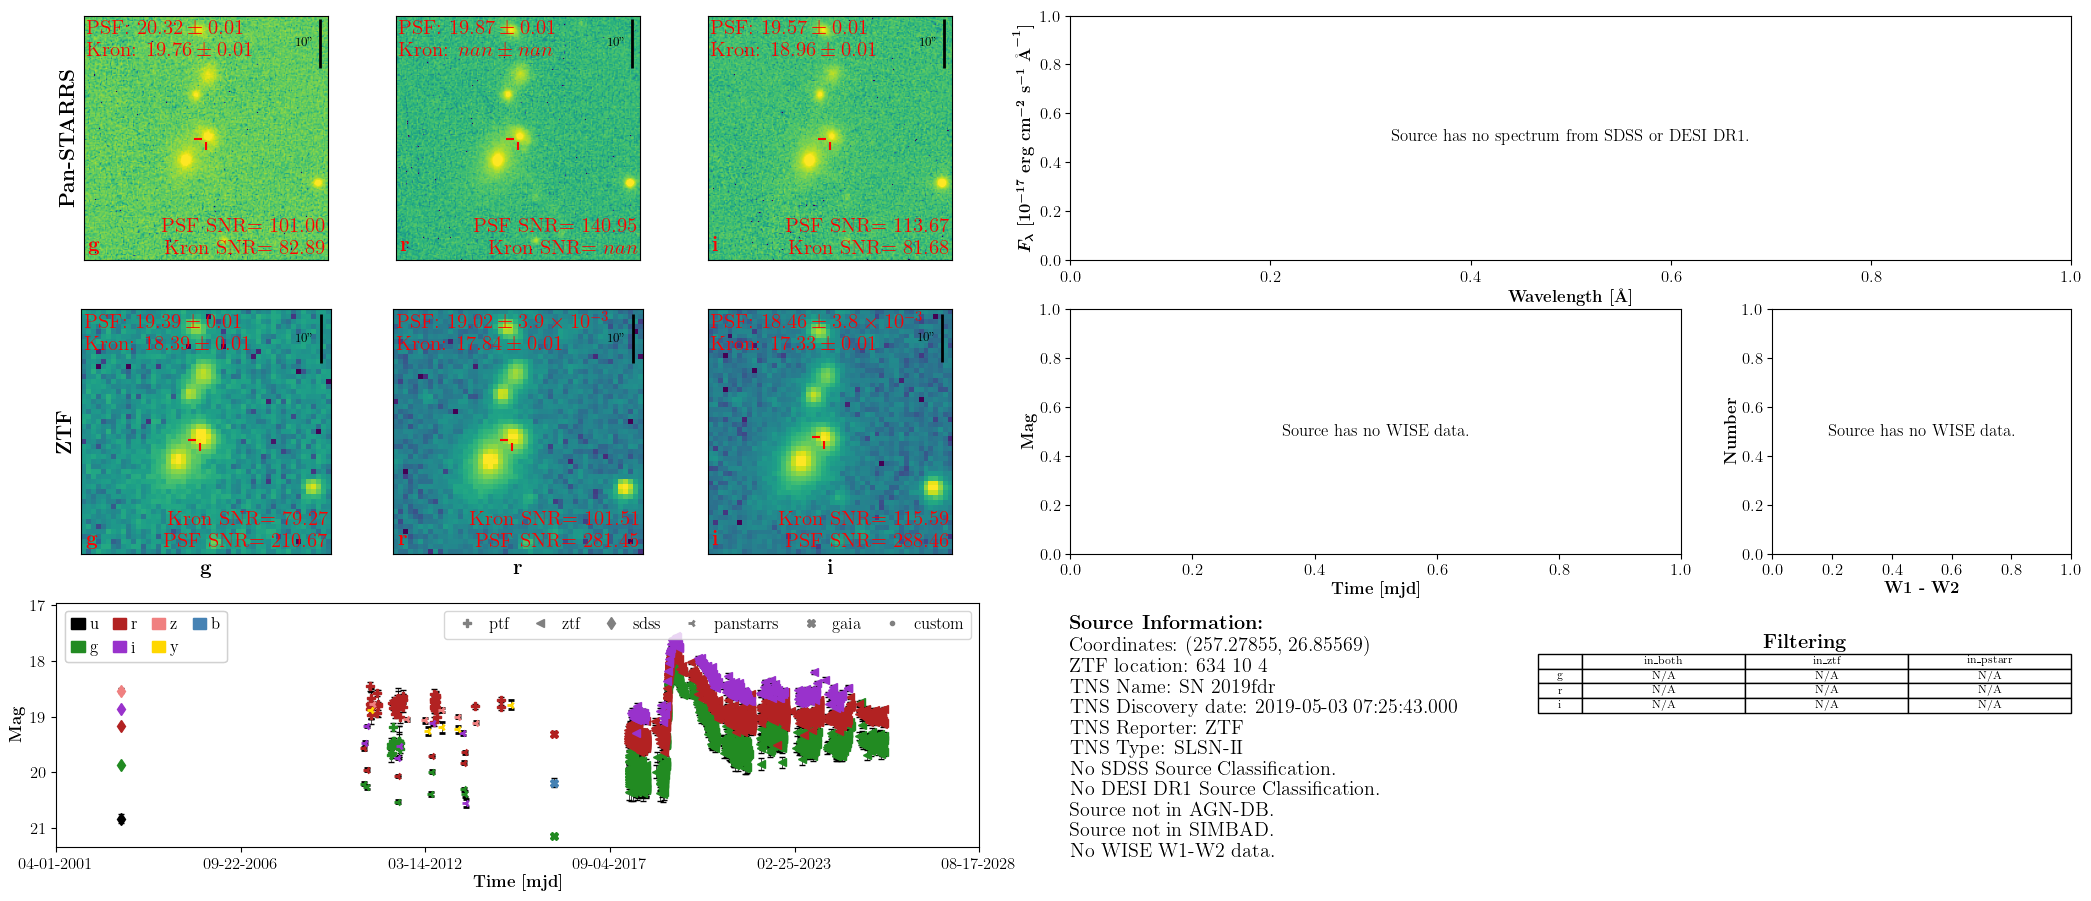

In [40]:
plot_and_save(jwst_srcs, 'SN 2019fdr')

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=000394+AND+ccdid=07+AND+qid=2

Checking if image already downloaded and valid: ztf_000394_zr_c07_q2_refimg.fits
Checking if image already downloaded and valid: ztf_000394_zg_c07_q2_refimg.fits
Checking if image already downloaded and valid: ztf_000394_zi_c07_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000394_zg_c07_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000394_zr_c07_q2_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_000394_zi_c07_q2_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Source at (349.7240294820334, -10.584928512027581) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (349.7240294820334, -10.584928512027581) has no spectrum in DESI DR1.


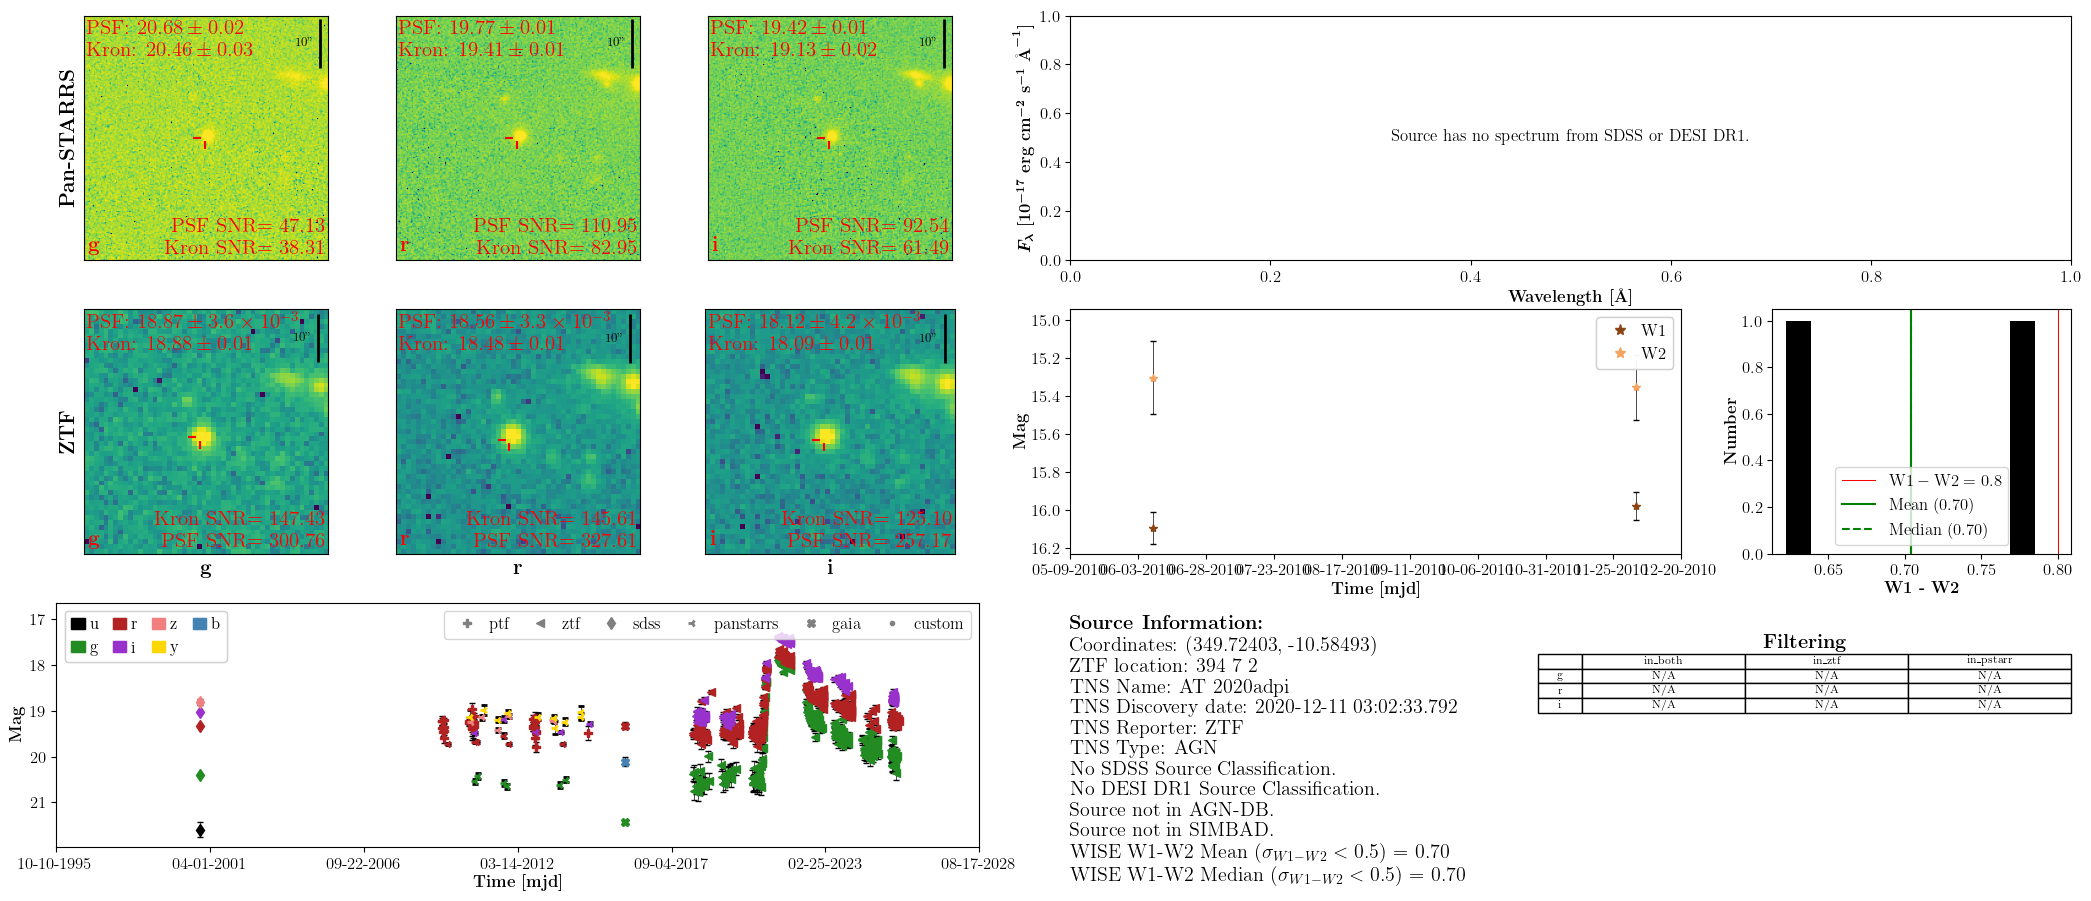

In [41]:
plot_and_save(jwst_srcs, 'AT 2020adpi')

### Not in the catalog

Blank catalog row; all data from the live services.

In [42]:
jwst_miss_srcs = {name: uncatalogued_source(ra, dec) for name, ra, dec in jwst_misses}

Falling back on ZTF image metadata with coordinate query...
Falling back on ZTF image metadata with coordinate query...
Falling back on ZTF image metadata with coordinate query...


Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=001762+AND+ccdid=01+AND+qid=2
Failed to download a valid image from https://irsa.ipac.caltech.edu/ibe/data/ztf/products/deep/00/field001762/zg/ccd01/q2/ztf_001762_zg_c01_q2_refimg.fits after 3 attempts.
Failed to download a valid image from https://irsa.ipac.caltech.edu/ibe/data/ztf/products/deep/00/field001762/zr/ccd01/q2/ztf_001762_zr_c01_q2_refimg.fits after 3 attempts.
No ZTF g image found for the specified RA and DEC.
Traceback:
Traceback (most recent call last):
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 1005, in plot_postage_stamps
    self.postage_stamps['ZTF'].plot_cutout(band=band, ax=axes[1], **kwargs)
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 254, in plot_cutout
    if self.images[band] is None:
       ^^^^^^^^^^^
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 

/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Source at (259.982708, 41.680411) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

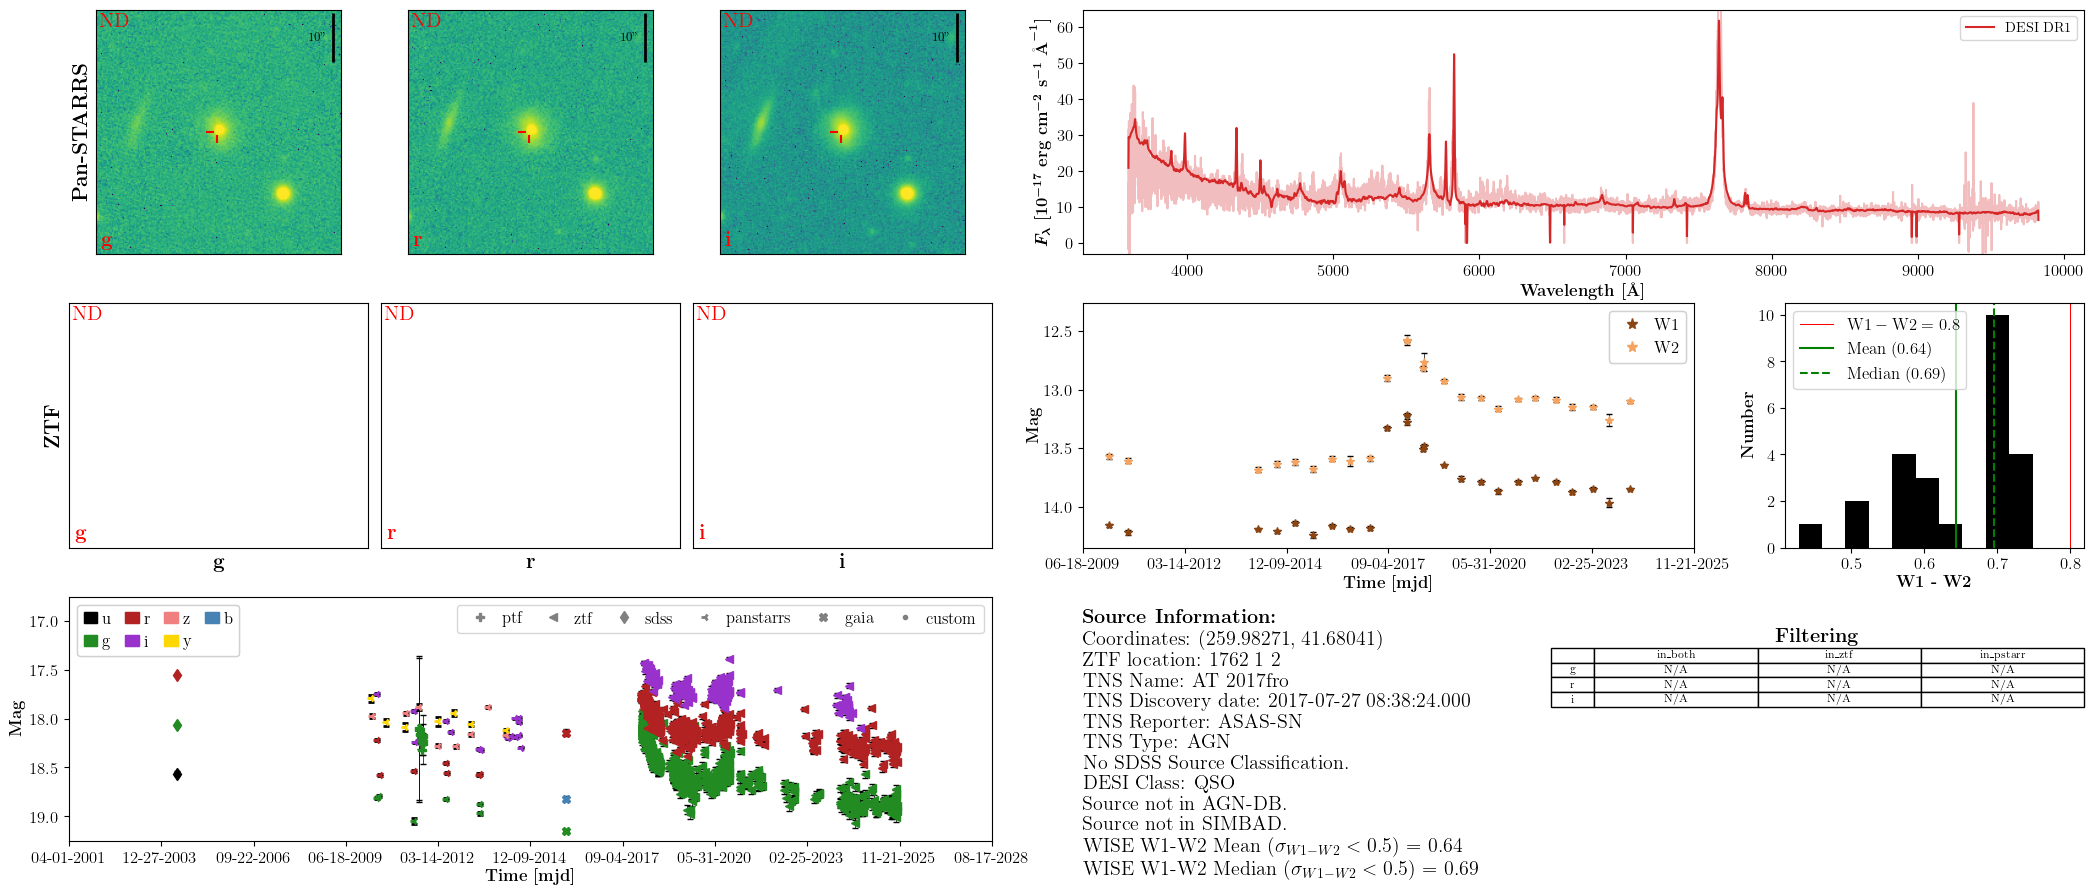

In [25]:
plot_and_save(jwst_miss_srcs, 'AT 2017fro')

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=001629+AND+ccdid=10+AND+qid=1
Checking if image already downloaded and valid: ztf_001629_zr_c10_q1_refimg.fits

Checking if image already downloaded and valid: ztf_001629_zg_c10_q1_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_001629_zr_c10_q1_refimg.fits
Image is valid at /Users/adamboesky/Research/long_transients/Data/ztf_data/ztf_001629_zg_c10_q1_refimg.fits
Local store has no custom; falling back to the service.
Querying custom catalog for light curve...
Local store has no ptf; falling back to the service.
Querying ptf catalog for light curve...
Local store has no neowise; falling back to the service.
Querying neowise catalog for light curve...
Local store has no panstarrs; falling back to the service.
Querying panstarrs catalog for light curve...
Pan-STARRS objid not found. Falling back on coordinate query...
Local store has no wise; falling ba

/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Getting source spectrum from SDSS (spec-1573-53226-0302.fits)...
Getting source spectrum from DESI DR1 (SPARCL)...


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

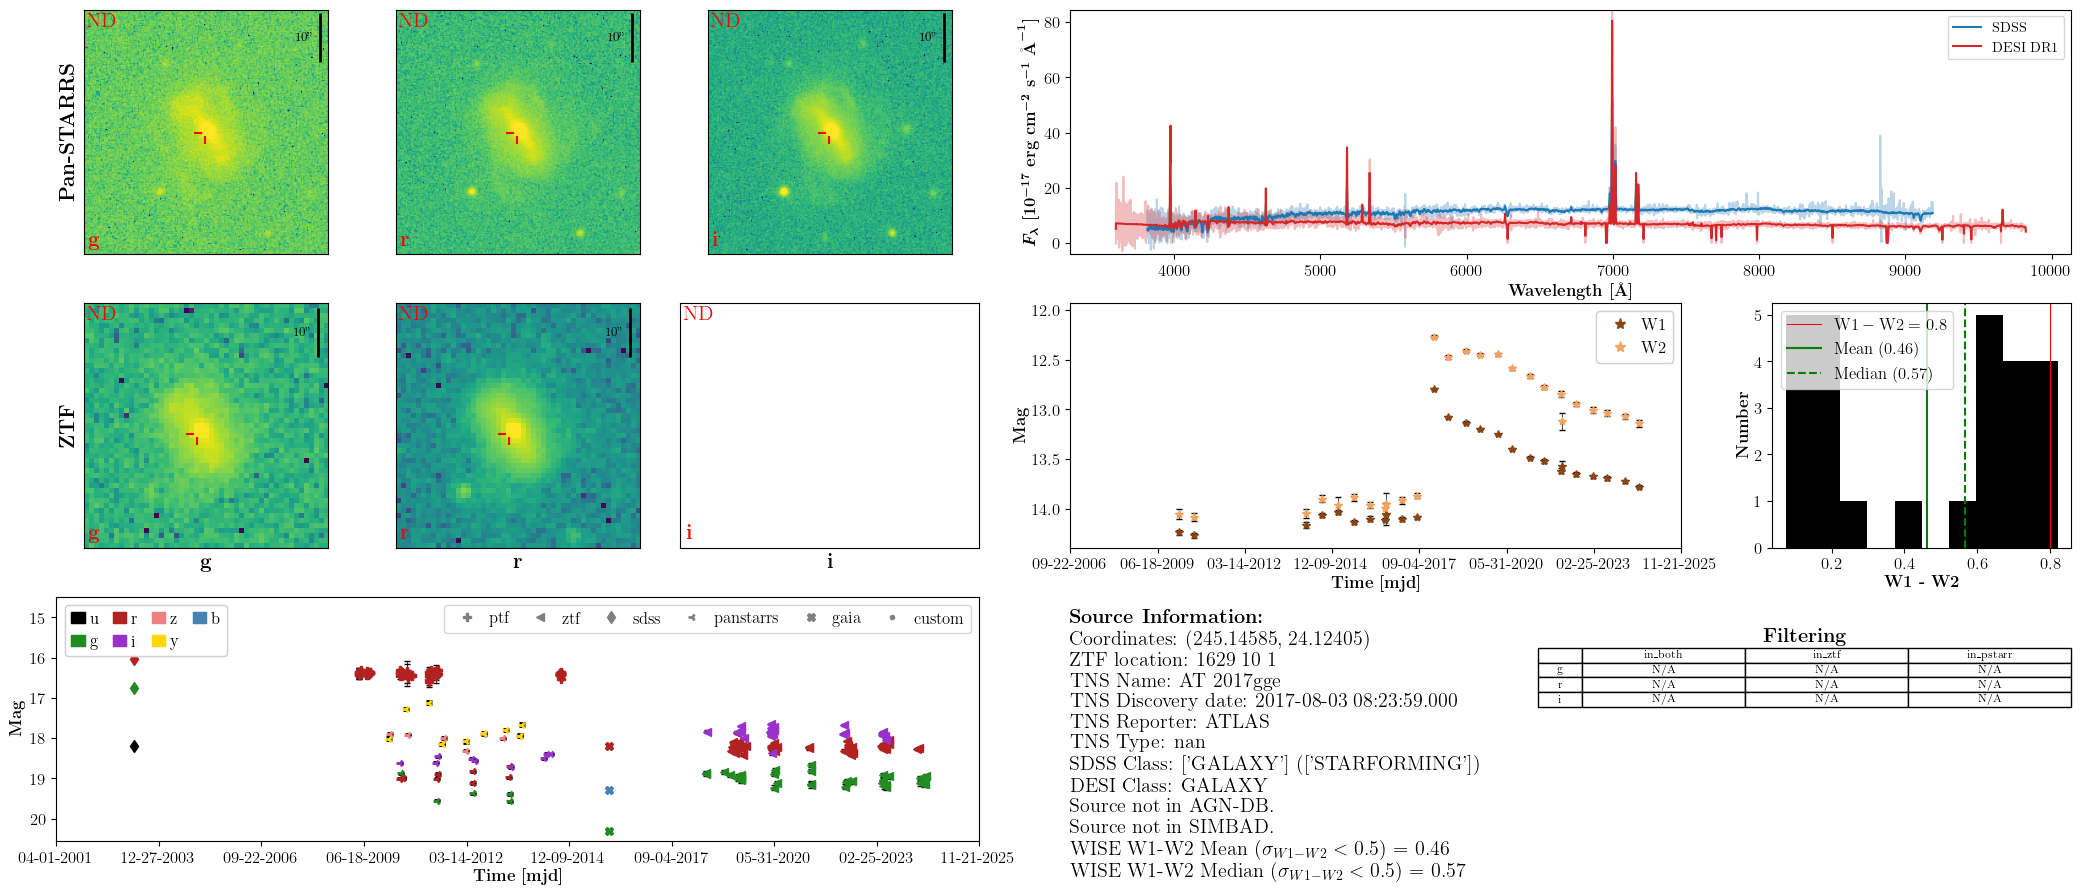

In [26]:
plot_and_save(jwst_miss_srcs, 'AT 2017gge')

Querying metadata from https://irsa.ipac.caltech.edu/ibe/search/ztf/products/deep?WHERE=field=001796+AND+ccdid=13+AND+qid=3
Failed to download a valid image from https://irsa.ipac.caltech.edu/ibe/data/ztf/products/deep/00/field001796/zr/ccd13/q3/ztf_001796_zr_c13_q3_refimg.fits after 3 attempts.
No ZTF r image found for the specified RA and DEC.
Traceback:
Traceback (most recent call last):
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 1005, in plot_postage_stamps
    self.postage_stamps['ZTF'].plot_cutout(band=band, ax=axes[1], **kwargs)
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 254, in plot_cutout
    if self.images[band] is None:
       ^^^^^^^^^^^
  File "/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py", line 167, in images
    self._images, self._WCSs = self.get_images()
                               ^^^^^^^^^^^^^^^^^
  File "/Users/adamboesky/Research/long_transients/Source_An

/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1351: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(


Source at (232.765417, 53.40535) has no spectrum in SDSS.
Getting source spectrum from DESI DR1 (SPARCL)...
Source at (232.765417, 53.40535) has no spectrum in DESI DR1.


/Users/adamboesky/Research/long_transients/Source_Analysis/Sources.py:1486: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  ax.errorbar(
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


array([array([[<Axes: ylabel='\\textbf{Pan-STARRS}'>, <Axes: >, <Axes: >],
              [<Axes: xlabel='\\textbf{g}', ylabel='\\textbf{ZTF}'>,
               <Axes: xlabel='\\textbf{r}'>, <Axes: xlabel='\\textbf{i}'>]],
             dtype=object)                                                  ,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{Wavelength [\\AA]}', ylabel='\\boldmath$F_\\lambda \\ [10^{-17} \\ \\rm{erg} \\ \\rm{cm}^{-2} \\ \\rm{s}^{-1} \\ \\rm{\\AA}^{-1}]$'>,
       <Axes: xlabel='\\textbf{Time [mjd]}', ylabel='\\textbf{Mag}'>,
       <Axes: xlabel='\\textbf{W1 - W2}', ylabel='\\textbf{Number}'>],
      dtype=object)

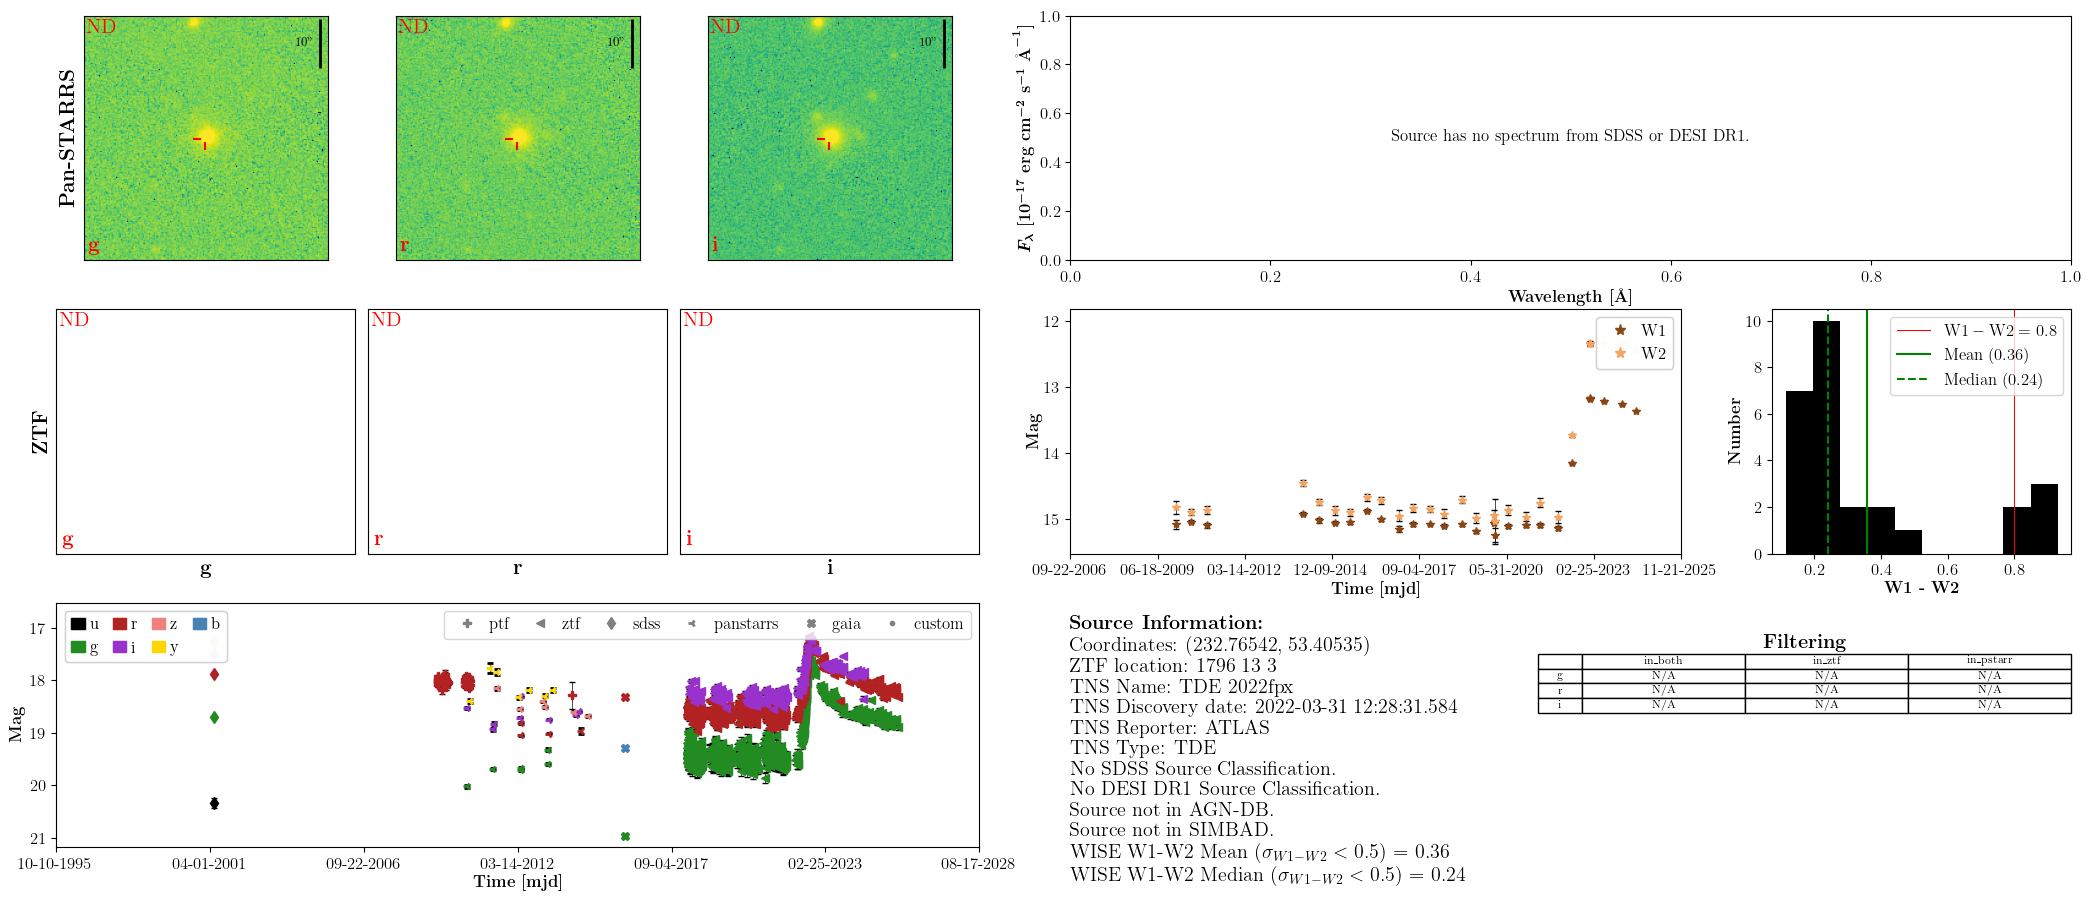

In [27]:
plot_and_save(jwst_miss_srcs, 'TDE 2022fpx')